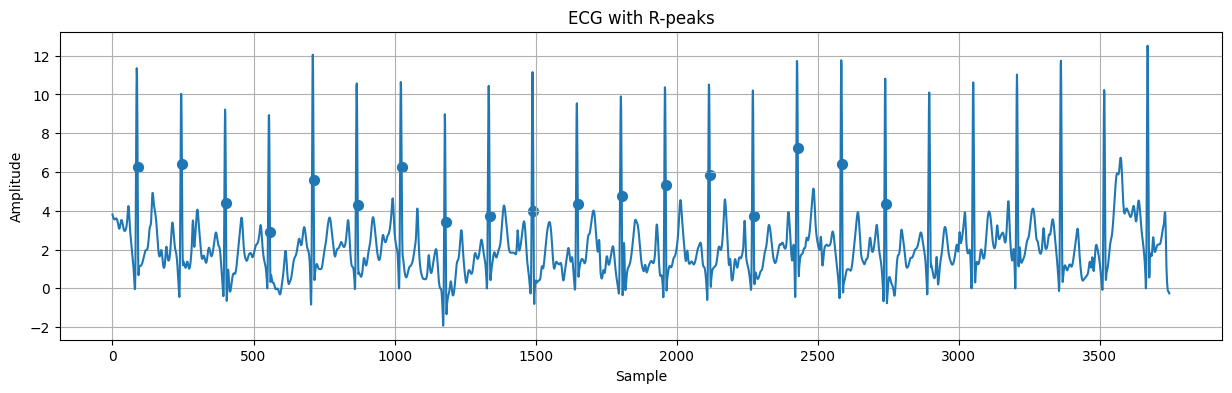

In [62]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt(r"Heartprint\Heartprint\Session-1\100\20120627_1459_02_ECG.txt")

ecg = data[:3747]

r_peaks = data[3747:3765].astype(int)
r_peaks = r_peaks[r_peaks > 0]

plt.figure(figsize=(15,4))
plt.plot(ecg)

plt.scatter(
    r_peaks,
    ecg[r_peaks],
    s=50,
    marker='o'
)

plt.title("ECG with R-peaks")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

In [48]:
import numpy as np
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs=250, lowcut=0.5, highcut=40):
    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        N=4,
        Wn=[low, high],
        btype='band'
    )

    filtered = filtfilt(b, a, signal)

    return filtered

In [49]:
import neurokit2 as nk

def detect_rpeaks(ecg, fs=250):

    signals, info = nk.ecg_process(
        ecg,
        sampling_rate=fs
    )

    return info["ECG_R_Peaks"]

In [50]:
def segment_heartbeat(signal, r_peaks, left=100, right=150):

    beats = []

    for r in r_peaks:

        start = r - left
        end = r + right

        if start >= 0 and end < len(signal):

            beat = signal[start:end]

            beats.append(beat)

    return np.array(beats)

In [51]:
def process_ecg_segment(ecg):
    ecg = bandpass_filter(ecg)
    r_peaks = detect_rpeaks(ecg)
    segments = segment_heartbeat(
        ecg,
        r_peaks
    )
    return segments

In [52]:
seg = process_ecg_segment(ecg)
print(seg.shape)
print(type(seg))

c:\Users\souvi\Desktop\HEART_PRINT\ecg\Lib\site-packages\neurokit2\epochs\epochs_create.py:180: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  buffer.select_dtypes(exclude=["int", "int64"]).replace({0.0: np.nan}, inplace=True)
c:\Users\souvi\Desktop\HEART_PRINT\ecg\Lib\site-packages\neurokit2\epochs\epochs_create.py:180: ChainedAssign

(22, 250)
<class 'numpy.ndarray'>


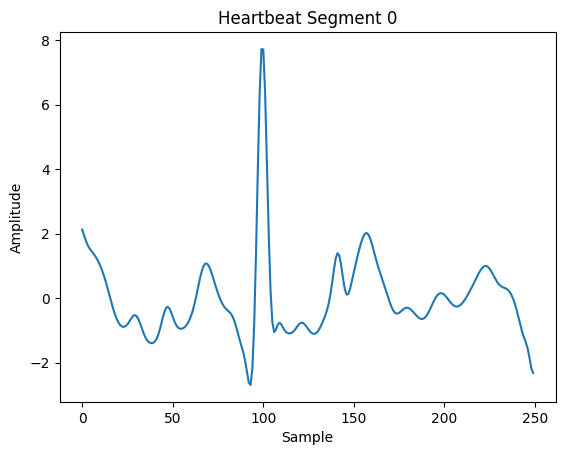

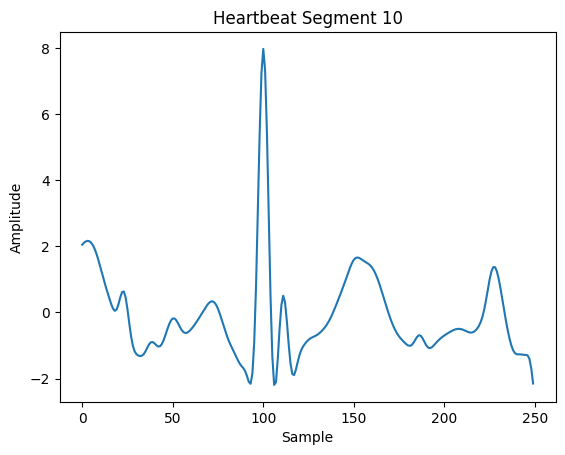

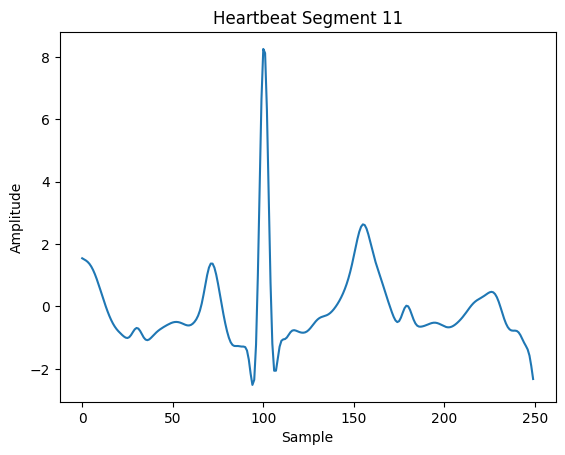

In [53]:
plt.plot(seg[0])
plt.title("Heartbeat Segment 0")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.show()

plt.plot(seg[10])
plt.title("Heartbeat Segment 10")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.show()

plt.plot(seg[11])
plt.title("Heartbeat Segment 11")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.show()

In [54]:
print(np.mean(seg[11]))
print(np.std(seg[11]))
print(np.min(seg[11]))
print(np.max(seg[11]))

-0.08602693409635838
1.375318179781389
-2.514625709137932
8.254181069820667


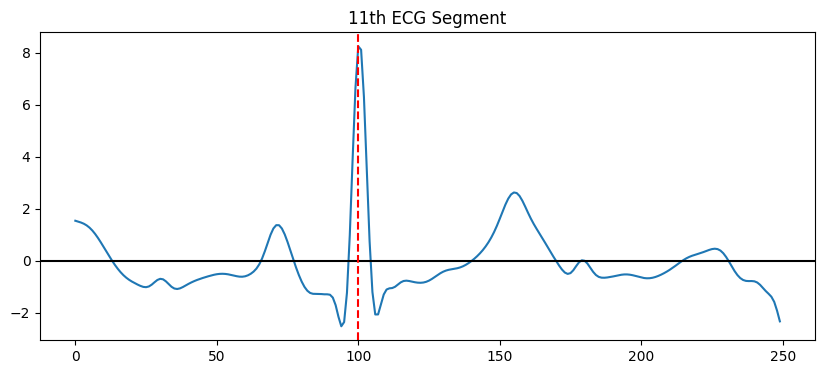

In [55]:
plt.figure(figsize=(10,4))
plt.plot(seg[11])
plt.axhline(0, color='black')
plt.axvline(100, color='red', linestyle='--')
plt.title("11th ECG Segment")
plt.show()

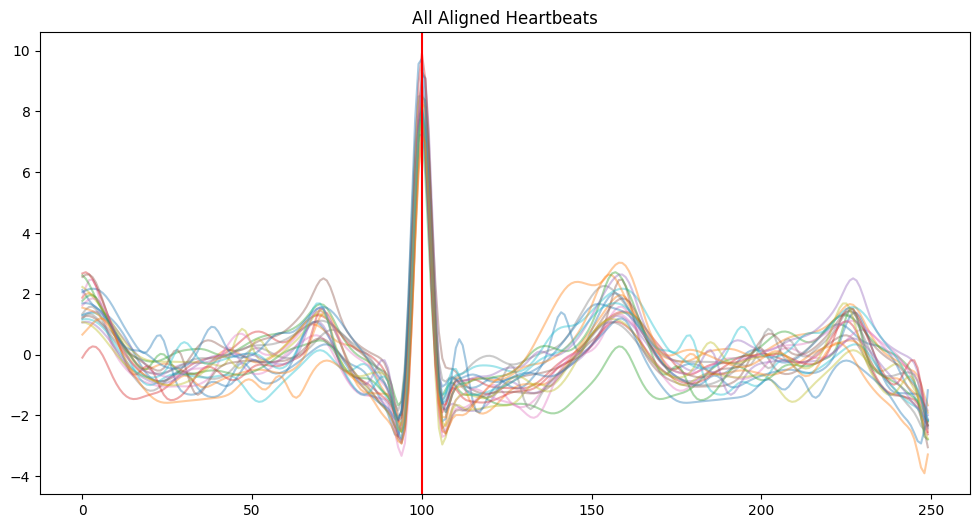

In [56]:
plt.figure(figsize=(12,6))

for s in seg:
    plt.plot(s, alpha=0.4)

plt.axvline(100, color='red')
plt.title("All Aligned Heartbeats")
plt.show()

In [57]:
import pywt
import cv2

def generate_cwt_image(signal, img_size):

    wavelets = [
        'mexh',
        'morl',
        'gaus1'
    ]

    scales = np.arange(1,128)

    channels = []

    for wavelet in wavelets:

        coeffs, _ = pywt.cwt(
            signal,
            scales,
            wavelet
        )

        scalogram = np.abs(coeffs)

        scalogram = cv2.resize(
            scalogram,
            (img_size, img_size)
        )

        scalogram = (
            scalogram - scalogram.min()
        ) / (
            scalogram.max() - scalogram.min() + 1e-8
        )

        scalogram = (
            scalogram * 255
        ).astype(np.uint8)

        channels.append(scalogram)

    image = np.stack(
        channels,
        axis=-1
    )

    return image

In [58]:
print(type(seg))
print(type(seg[11]))
print(np.shape(seg[11]))
print(seg[11])

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(250,)
[ 1.54446572e+00  1.51137048e+00  1.47559675e+00  1.42953359e+00
  1.36600237e+00  1.28010179e+00  1.16991166e+00  1.03640762e+00
  8.82943264e-01  7.14507592e-01  5.36901833e-01  3.55999938e-01
  1.77230937e-01  5.30759408e-03 -1.55879281e-01 -3.03291937e-01
 -4.34754443e-01 -5.49002717e-01 -6.45890179e-01 -7.26795751e-01
 -7.94950201e-01 -8.54934195e-01 -9.10551651e-01 -9.61276104e-01
 -9.99361901e-01 -1.01095833e+00 -9.83091958e-01 -9.14005672e-01
 -8.20194296e-01 -7.33775836e-01 -6.89526487e-01 -7.08108209e-01
 -7.85278730e-01 -8.93664626e-01 -9.96078482e-01 -1.06241891e+00
 -1.08057844e+00 -1.05651840e+00 -1.00603504e+00 -9.45090766e-01
 -8.84268956e-01 -8.28334717e-01 -7.78431971e-01 -7.34173202e-01
 -6.94586204e-01 -6.58385182e-01 -6.24307616e-01 -5.91703701e-01
 -5.61040187e-01 -5.33935416e-01 -5.12661855e-01 -4.99385458e-01
 -4.95514699e-01 -5.01382166e-01 -5.16208241e-01 -5.38089873e-01
 -5.63792594e-01 -5.88450622e-01 -6

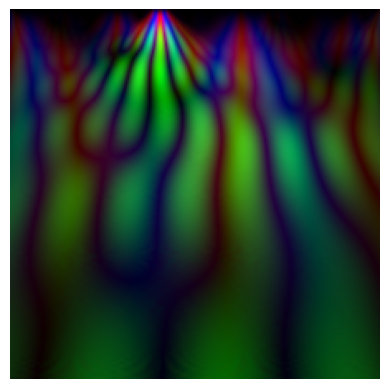

In [59]:
IMG_SIZE = 224

cwt_image = generate_cwt_image(
                        seg[11],
                        img_size=IMG_SIZE)

plt.imshow(cwt_image, cmap='gray')
plt.axis('off')
plt.show()

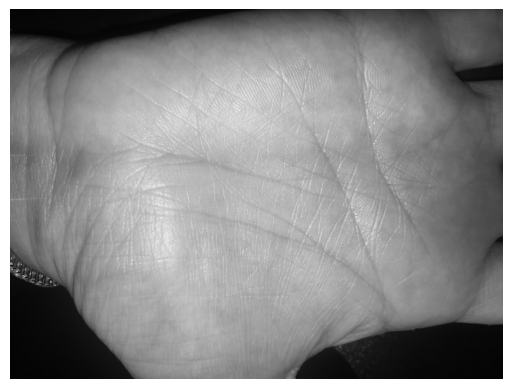

In [77]:
img = cv2.imread(r"020_F_0.JPG", cv2.IMREAD_GRAYSCALE)

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

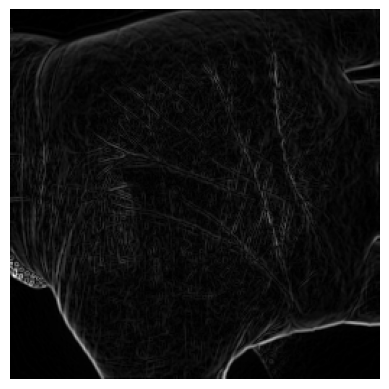

In [76]:
img = Image.open("020_F_0.JPG")

img = img.resize((256, 256), Image.Resampling.LANCZOS)

img = img.convert("L")

img = np.array(img)

gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

mag = np.sqrt(gx**2 + gy**2)

mag = cv2.normalize(
    mag,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


plt.imshow(mag, cmap='gray')
plt.axis('off')
plt.show()


In [64]:
from PIL import Image

def preprocess_palmprint(
    image_path,
    output_size=224
):

    pil_img = Image.open(
        image_path
    ).convert("RGB")

    img = np.array(pil_img)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    gray = clahe.apply(gray)

    gray = cv2.GaussianBlur(
        gray,
        (3,3),
        0
    )

    h, w = gray.shape

    crop_ratio = 0.7

    new_h = int(h * crop_ratio)
    new_w = int(w * crop_ratio)

    start_y = (h - new_h) // 2
    start_x = (w - new_w) // 2

    gray = gray[
        start_y:start_y + new_h,
        start_x:start_x + new_w
    ]

    gray = cv2.resize(
        gray,
        (output_size, output_size)
    )

    return gray

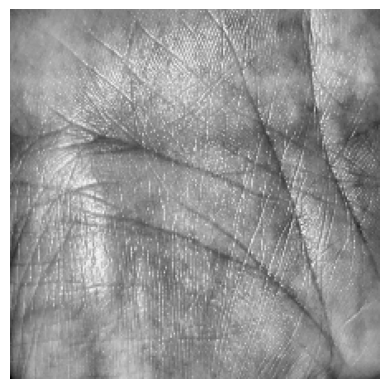

In [72]:
import cv2
import matplotlib.pyplot as plt


roi = preprocess_palmprint(image_path=r"020_F_0.JPG")

plt.imshow(roi, cmap='gray')
plt.axis('off')
plt.show()

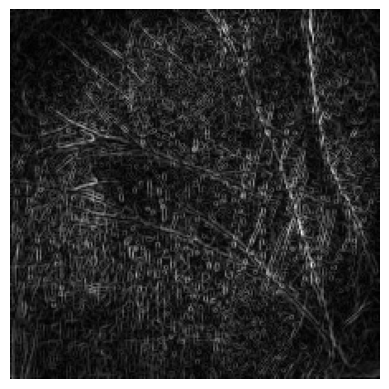

In [73]:
gx = cv2.Sobel(roi, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(roi, cv2.CV_64F, 0, 1, ksize=3)

mag = np.sqrt(gx**2 + gy**2)

mag = cv2.normalize(
    mag,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


plt.imshow(mag, cmap='gray')
plt.axis('off')
plt.show()

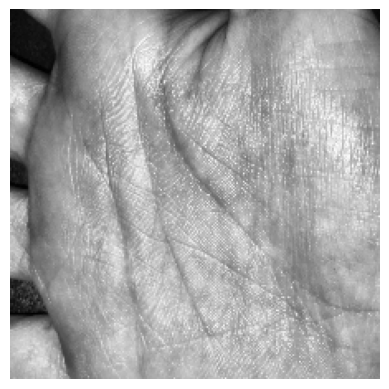

In [74]:
roi = preprocess_palmprint(image_path=r"009_F_0.JPG")

plt.imshow(roi, cmap='gray')
plt.axis('off')
plt.show()

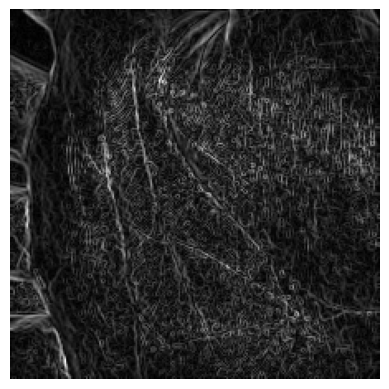

In [75]:
gx = cv2.Sobel(roi, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(roi, cv2.CV_64F, 0, 1, ksize=3)

mag = np.sqrt(gx**2 + gy**2)

mag = cv2.normalize(
    mag,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


plt.imshow(mag, cmap='gray')
plt.axis('off')
plt.show()

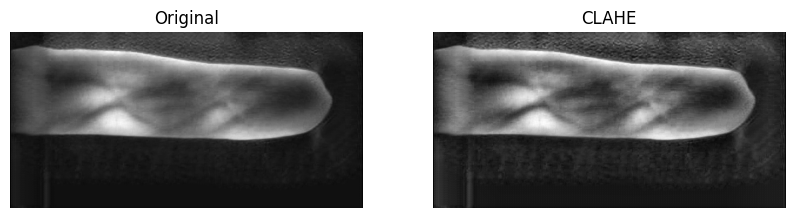

In [70]:
img = cv2.imread(r"Finger_Vein\01001_001_Shift (2).png", cv2.IMREAD_GRAYSCALE)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

img_uint8 = cv2.normalize(
    img,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)


# Apply CLAHE
clahe_img = clahe.apply(img_uint8)

# Display
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(clahe_img, cmap='gray')
plt.title("CLAHE")
plt.axis('off')

plt.show()